# 05 · Results and error analysis

What the final models score on test, where they go wrong, and why (research question 4).

This notebook builds on the three before it: `02_baseline.ipynb` (KNN and logistic regression on
pixels, HOG and colour histograms), `03_cnn.ipynb` (simple CNN from scratch, with and without
augmentation) and `04_transfer.ipynb` (ResNet-50, test-time augmentation, seed ensemble). Sections
1–3 gather their test results in one place; sections 4–9 are the error analysis.

1. Final results: every model on the test set, CNNs as mean ± std over 3 seeds, plus
   test-time augmentation (TTA) and a seed ensemble for ResNet-50
2. Before vs after augmentation
3. Per-class F1 and pooled confusion matrices
4. Stable vs unstable mistakes (do all 3 ResNet seeds make the same error?)
5. Same-session frames: does every test image have a near-identical training image?
6. Grad-CAM: what the ResNet-50 and simple CNN look at when they are wrong
7. LIME: what the colour-histogram KNN responds to
8. Error-cause gallery + tagging sheet for the team
9. Are mistakes darker, blurrier or less colourful than correct predictions?
10. Takeaways

**Split.** Every result uses the authors' split as published on Kaggle (`labels/*_subset0.csv`,
fold 0): 10,501 train, 3,501 val and 3,507 test images, no image in two splits. Labels come from
`labels.csv` (one image has a different label in the fold files; see `src/data/kaggle_split.py`).

**Leakage note.** No test image is used for training or for any choice: k, C, the best epoch
and the use of TTA / the seed ensemble are picked on the validation set, and each CNN's
augmentation was chosen on validation data in earlier tuning runs, before these runs. This notebook
reads saved results and predictions, loads the saved CNN checkpoints for Grad-CAM (section 6) and
refits the KNN on train for LIME (section 7). Nothing here feeds back into a model.

**Running it.** Sections 6–7 need the `*_kaggle0_s1.pt` checkpoints in `experiments/checkpoints/`
(not in git) and the `grad-cam` and `lime` packages; every other section only needs the files in
the repo and `data/images/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage, display
from scipy.stats import mannwhitneyu

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
from src.evaluation import explain
from src.evaluation.aggregate import top_pooled_confusions

%matplotlib inline
# ^ src.evaluation.confusion selects the non-interactive Agg backend on import; switch back so figures show

METRICS = ROOT / 'results' / 'metrics'
PREDS = ROOT / 'results' / 'predictions'
CMS = ROOT / 'results' / 'confusion_matrices'
CFG = ROOT / 'experiments' / 'configs'
IMG_DIR = ROOT / 'data' / 'images'
FIG_DIR = ROOT / 'results' / 'figures' / 'error_analysis_kaggle0'
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPLIT = '_kaggle0'                                         # Kaggle split, fold 0
RESNET = 'resnet50_aug_geo_crop_30ep_bf16' + SPLIT         # flip + rotate + random crop
CNN = 'simple_cnn_aug_geo_colour_60ep_bf16' + SPLIT        # flip + rotate + colour jitter
SEEDS = [1, 2, 3]

def metrics(run):
    return json.loads((METRICS / f'{run}.json').read_text())

CLASSES = metrics(f'{RESNET}_s1')['config']['classes']
pd.set_option('display.precision', 3)
plt.rcParams['figure.dpi'] = 90

## 1. Final results on test

The last two rows add test-time augmentation (TTA) to the same 3 ResNet-50 checkpoints: each
image is scored in its 8 flip / 90° rotation views (the orientations training already uses) and
the softmax outputs are averaged; the ensemble also averages the 3 seeds. No retraining. Both
were chosen on val (`experiments/ITERATION_LOG.md` rows 12–13, `src/evaluation/tta.py`) before
test was scored. Sections 3–9 analyse the single-model predictions without TTA.

Where each row comes from: classical models in `02_baseline.ipynb` (section 4), simple CNN in `03_cnn.ipynb` (section 6), ResNet-50, TTA and the ensemble in `04_transfer.ipynb` (sections 5–6).

In [2]:
KEYS = ['macro_f1', 'macro_precision', 'macro_recall', 'accuracy']

def single(label, run):
    d = metrics(run)['splits']
    row = {'model': label, 'runs': 1, 'val macro F1': d['val']['model']['macro_f1']}
    row.update({k: f"{d['test']['model'][k]:.3f}" for k in KEYS})
    return row

def seeds(label, prefix):
    s = metrics(f'{prefix}_seeds')['splits']
    row = {'model': label, 'runs': len(SEEDS), 'val macro F1': s['val']['macro_f1']['mean']}
    row.update({k: f"{s['test'][k]['mean']:.3f} ± {s['test'][k]['std']:.3f}" for k in KEYS})
    return row

def tta(label, combo):
    t, v = (metrics(f'{RESNET}_tta_{split}')['results'] for split in ('test', 'val'))
    if f'{combo} (mean)' in t:   # each seed on its own: mean ± std
        return {'model': label, 'runs': len(SEEDS), 'val macro F1': v[f'{combo} (mean)']['macro_f1'],
                **{k: f"{t[f'{combo} (mean)'][k]:.3f} ± {t[f'{combo} (std)'][k]:.3f}" for k in KEYS}}
    return {'model': label, 'runs': len(SEEDS), 'val macro F1': v[combo]['macro_f1'],
            **{k: f'{t[combo][k]:.3f}' for k in KEYS}}

majority = metrics('knn_hist' + SPLIT)['splits']['test']['majority_baseline']
rows = [{'model': 'Majority class (always Negative)', 'runs': 1, 'val macro F1': np.nan,
         **{k: f'{majority[k]:.3f}' for k in KEYS}}]
rows += [single('KNN, raw pixels', 'knn_pixels' + SPLIT), single('KNN, HOG', 'knn_hog' + SPLIT),
         single('KNN, HSV colour histogram', 'knn_hist' + SPLIT),
         single('Logistic regression, raw pixels', 'logreg_pixels' + SPLIT), single('Logistic regression, HOG', 'logreg_hog' + SPLIT),
         single('Logistic regression, HSV colour histogram', 'logreg_hist' + SPLIT),
         single('Simple CNN, no augmentation', 'simple_cnn_noaug_60ep_bf16' + SPLIT + '_s1'),
         seeds('Simple CNN + flip/rotate/colour', CNN),
         single('ResNet-50, no augmentation', 'resnet50_noaug_30ep_bf16' + SPLIT + '_s1'),
         seeds('ResNet-50 + flip/rotate/crop', RESNET),
         tta('ResNet-50 + flip/rotate/crop, with TTA', 'single + TTA'),
         tta('ResNet-50, ensemble of 3 seeds, with TTA', 'ensemble + TTA')]
results = pd.DataFrame(rows).set_index('model').rename(columns={k: f'test {k}' for k in KEYS})
results.to_csv(FIG_DIR / 'final_results.csv')
results

,runs,val macro F1,test macro_f1,test macro_precision,test macro_recall,test accuracy
model,,,,,,
Majority class (always Negative),1,NaN,0.076,0.058,0.111,0.520
"KNN, raw pixels",1,0.192,0.192,0.204,0.207,0.434
"KNN, HOG",1,0.125,0.128,0.149,0.131,0.388
"KNN, HSV colour histogram",1,0.608,0.613,0.650,0.586,0.721
"Logistic regression, raw pixels",1,0.239,0.234,0.268,0.220,0.504
"Logistic regression, HOG",1,0.160,0.166,0.185,0.162,0.434
"Logistic regression, HSV colour histogram",1,0.384,0.375,0.464,0.341,0.595
"Simple CNN, no augmentation",1,0.877,0.870,0.875,0.865,0.900
Simple CNN + flip/rotate/colour,3,0.907,0.905 ± 0.005,0.915 ± 0.004,0.895 ± 0.006,0.925 ± 0.004


## 2. Before vs after augmentation

A summary of `03_cnn.ipynb` sections 4–6 and `04_transfer.ipynb` sections 4–5, which show the full training curves and the train/val loss gap.

Same model, schedule and seed 1; the only change is train-time augmentation (one factor).
The augmented configs were also run with seeds 2 and 3, so their spread shows how much of
a gap seed noise alone could explain. The no-augmentation runs have one seed each.

In [3]:
pairs = [('Simple CNN', 'simple_cnn_noaug_60ep_bf16' + SPLIT, CNN), ('ResNet-50', 'resnet50_noaug_30ep_bf16' + SPLIT, RESNET)]
rows = []
for name, noaug, aug in pairs:
    n, a = metrics(f'{noaug}_s1')['splits'], metrics(f'{aug}_s1')['splits']
    s = metrics(f'{aug}_seeds')['splits']
    for split in ('val', 'test'):
        rows.append({'model': name, 'split': split,
                     'no aug (s1)': n[split]['model']['macro_f1'],
                     'aug (s1)': a[split]['model']['macro_f1'],
                     'gain (s1)': a[split]['model']['macro_f1'] - n[split]['model']['macro_f1'],
                     'aug mean (3 seeds)': s[split]['macro_f1']['mean'],
                     'aug std': s[split]['macro_f1']['std'],
                     'aug min': s[split]['macro_f1']['min']})
aug_table = pd.DataFrame(rows).set_index(['model', 'split'])
aug_table

no aug (s1)  aug (s1)  gain (s1)  aug mean (3 seeds)  \
model      split                                                         
Simple CNN val          0.877     0.906      0.029               0.907   
           test         0.870     0.902      0.032               0.905   
ResNet-50  val          0.876     0.925      0.050               0.924   
           test         0.870     0.929      0.058               0.923   

                    aug std  aug min  
model      split                      
Simple CNN val    5.980e-04    0.906  
           test   5.039e-03    0.902  
ResNet-50  val    3.473e-03    0.920  
           test   5.265e-03    0.919

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, noaug, aug) in zip(axes, pairs):
    for run, label, colour in [(f'{noaug}_s1', 'no augmentation', 'tab:grey'), (f'{aug}_s1', 'augmented', 'tab:blue')]:
        h = pd.DataFrame(metrics(run)['history'])
        ax.plot(h['epoch'], h['val_macro_f1'], color=colour, label=f'{label}: val macro F1')
        ax.plot(h['epoch'], h['train_acc'], color=colour, ls='--', alpha=0.6, label=f'{label}: train acc')
    ax.set_title(f'{name} (seed 1)')
    ax.set_xlabel('epoch')
axes[0].legend(fontsize=8, loc='lower right')
fig.tight_layout()
fig.savefig(FIG_DIR / 'augmentation_curves.png', bbox_inches='tight')

## 3. Per-class F1 and pooled confusion matrices

In [5]:
knn_pc = metrics('knn_hist' + SPLIT)['splits']['test']['model']['per_class']
ens_pc = metrics(f'{RESNET}_tta_test')['results']['ensemble + TTA']['per_class']
per_class = pd.DataFrame({
    'KNN colour hist': {c: knn_pc[c]['f1'] for c in CLASSES},
    'Simple CNN (mean)': {c: v['mean'] for c, v in metrics(f'{CNN}_seeds')['per_class_test_f1'].items()},
    'ResNet-50 (mean)': {c: v['mean'] for c, v in metrics(f'{RESNET}_seeds')['per_class_test_f1'].items()},
    'ResNet-50 ensemble + TTA': {c: ens_pc[c]['f1'] for c in CLASSES},
    'ResNet-50 std': {c: v['std'] for c, v in metrics(f'{RESNET}_seeds')['per_class_test_f1'].items()},
    'test images': {c: knn_pc[c]['support'] for c in CLASSES},
}).loc[CLASSES]
ax = per_class.iloc[:, :4].plot.bar(figsize=(10, 3.6), width=0.8, rot=30)
ax.set_ylabel('test F1'); ax.set_ylim(0, 1); ax.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig(FIG_DIR / 'per_class_f1.png', bbox_inches='tight')
per_class.sort_values('ResNet-50 (mean)')

,KNN colour hist,Simple CNN (mean),ResNet-50 (mean),ResNet-50 ensemble + TTA,ResNet-50 std,test images
Chinee apple,0.427,0.856,0.871,0.909,0.007,226
Snake weed,0.479,0.825,0.881,0.912,0.018,204
Parthenium,0.607,0.924,0.919,0.958,0.009,205
Lantana,0.624,0.898,0.924,0.952,0.015,213
Prickly acacia,0.712,0.894,0.925,0.948,0.005,213
Rubber vine,0.570,0.916,0.925,0.942,0.016,202
Siam weed,0.577,0.919,0.947,0.958,0.005,215
Parkinsonia,0.692,0.965,0.952,0.983,0.015,207
Negative,0.827,0.948,0.961,0.972,0.003,1822


resnet50_aug_geo_crop_30ep_bf16_kaggle0 - top mistakes, mean count per run (true -> pred):
       Rubber vine -> Negative        15.7
      Chinee apple -> Negative        15.7
           Lantana -> Negative        14.3
        Snake weed -> Negative        13.7
        Snake weed -> Chinee apple    13.0
         Siam weed -> Negative        13.0
simple_cnn_aug_geo_colour_60ep_bf16_kaggle0 - top mistakes, mean count per run (true -> pred):
        Snake weed -> Negative        21.3
      Chinee apple -> Negative        21.3
           Lantana -> Negative        18.0
    Prickly acacia -> Negative        15.0
        Parthenium -> Negative        15.0
          Negative -> Prickly acacia  14.7


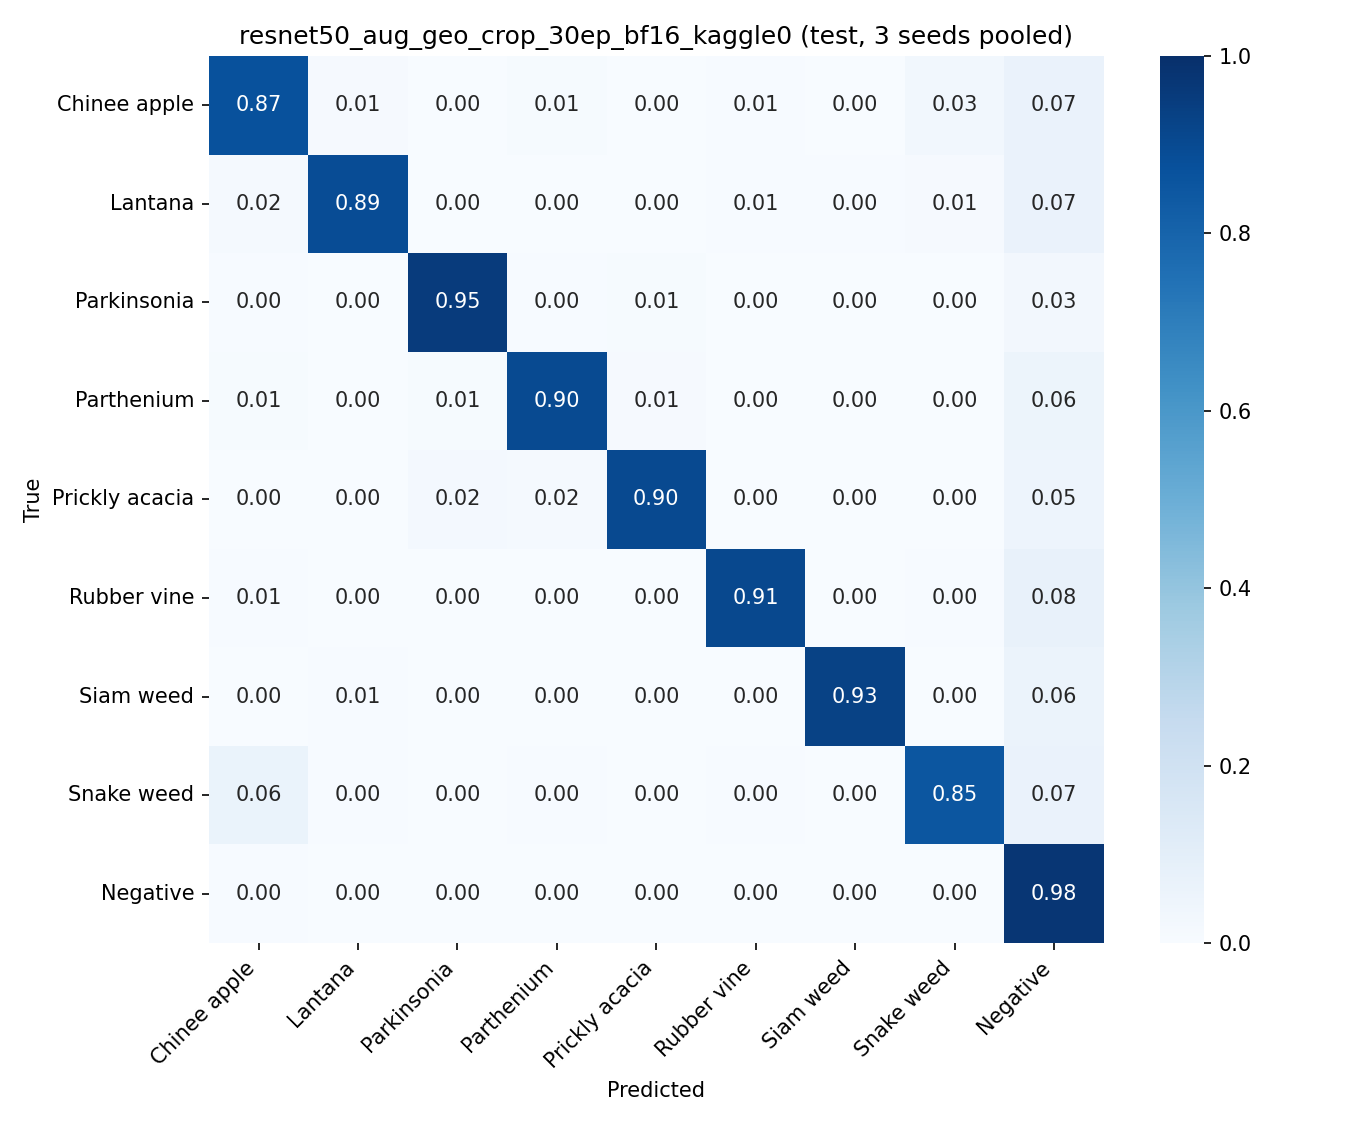

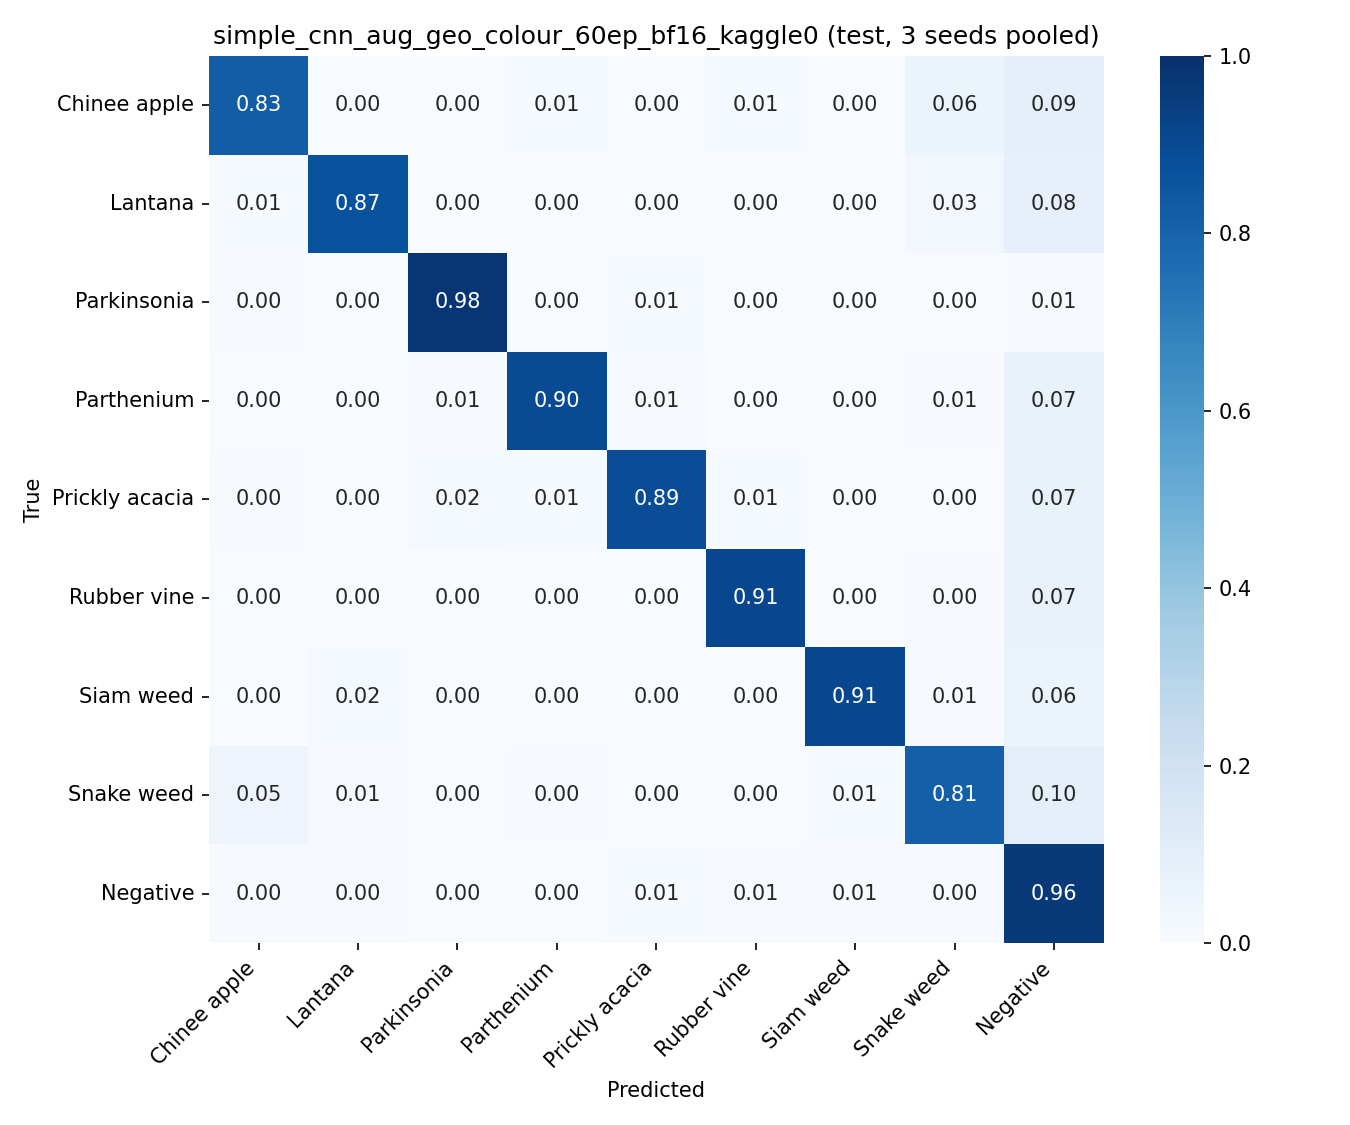

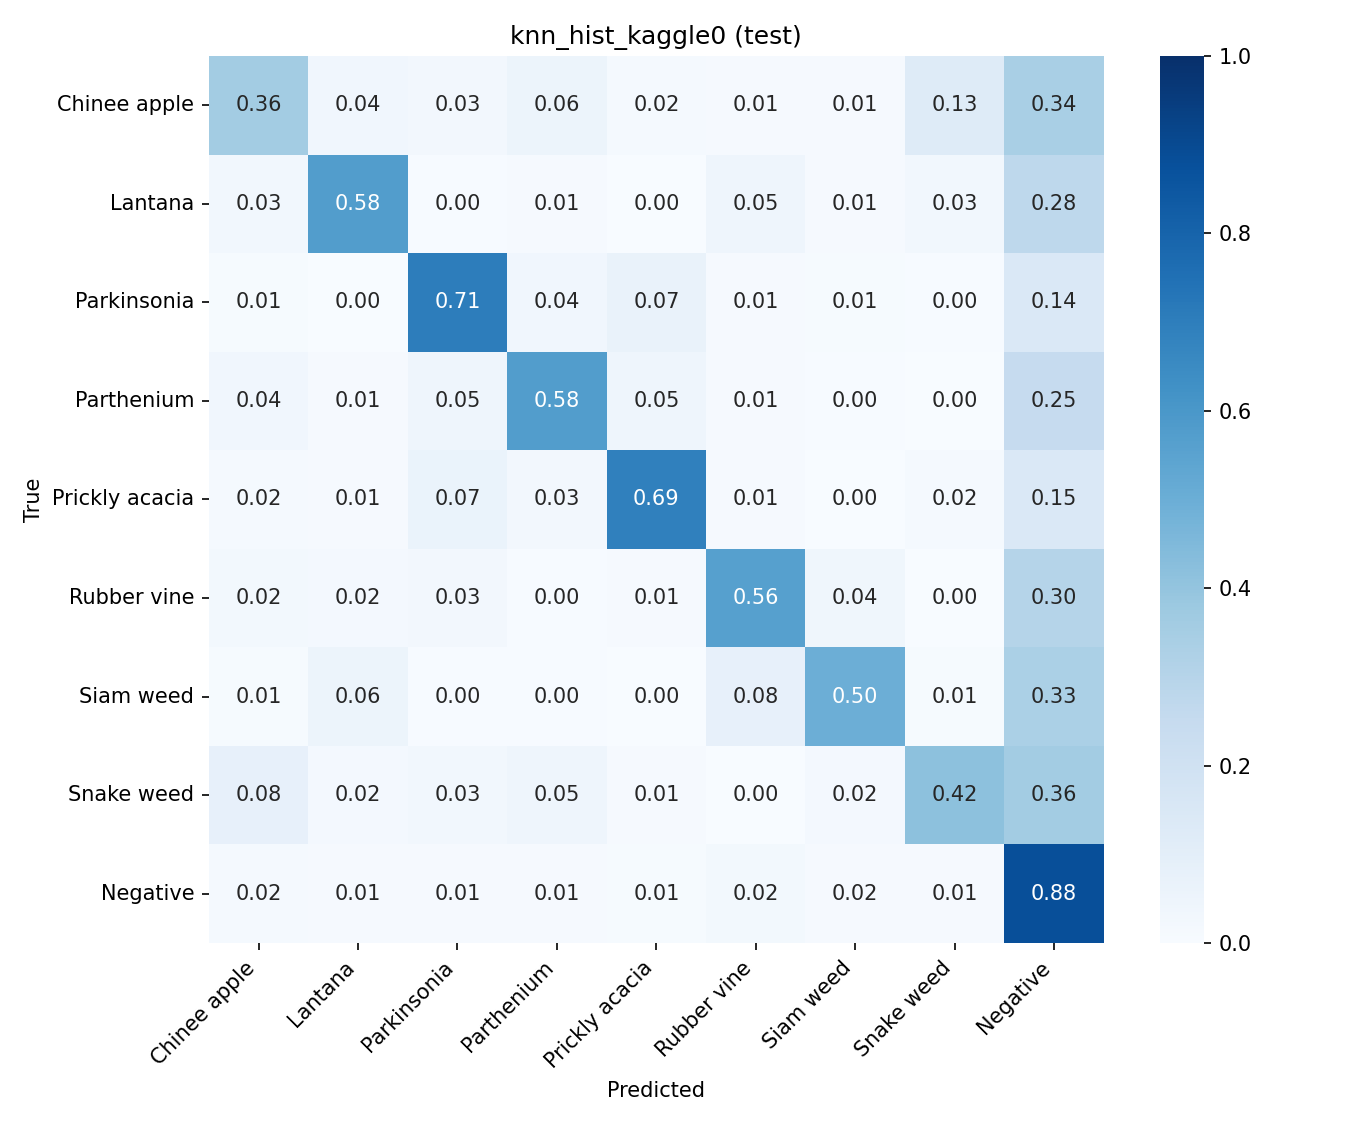

In [6]:
for prefix in (RESNET, CNN):
    print(prefix, '- top mistakes, mean count per run (true -> pred):')
    for t, p, n in top_pooled_confusions(metrics(f'{prefix}_seeds'), k=6):
        print(f'    {t:>14} -> {p:<14} {n:5.1f}')
display(ShowImage(filename=str(CMS / f'{RESNET}_seeds_test.png'), width=520))
display(ShowImage(filename=str(CMS / f'{CNN}_seeds_test.png'), width=520))
display(ShowImage(filename=str(CMS / f'knn_hist{SPLIT}_test.png'), width=520))

## 4. Stable vs unstable mistakes

All three ResNet seeds see the same test set. A mistake made by **all three** comes from the
image (look-alike species, an ambiguous or mislabelled photo). A mistake made by **one** seed
reflects training randomness. Most of the analysis below uses the stable mistakes.

In [7]:
def load_preds(prefix, seed):
    return pd.read_csv(PREDS / f'{prefix}_s{seed}_test.csv').set_index('Filename')

res = {s: load_preds(RESNET, s) for s in SEEDS}
test = res[1][['true']].copy()
test['n_wrong'] = sum((res[s]['pred'] != res[s]['true']).astype(int) for s in SEEDS)
test['mean_conf'] = sum(res[s]['confidence'] for s in SEEDS) / len(SEEDS)
test['pred_s1'] = res[1]['pred']
counts = test['n_wrong'].value_counts().sort_index().rename('test images')
print(counts.to_string())
print(f"\nwrong in all 3 seeds: {(test.n_wrong == 3).sum()} of {(test.n_wrong > 0).sum()} images wrong in any seed "
      f"({(test.n_wrong == 3).sum() / (test.n_wrong > 0).sum():.0%})")
stable = test[test.n_wrong == 3]
# among stable mistakes, how often do all three seeds predict the same wrong class?
same = (res[1].loc[stable.index, 'pred'] == res[2].loc[stable.index, 'pred']) & \
       (res[2].loc[stable.index, 'pred'] == res[3].loc[stable.index, 'pred'])
print(f'stable mistakes where all 3 seeds give the same wrong class: {same.mean():.0%}')
pd.crosstab(stable['true'], stable['pred_s1'], margins=True)

n_wrong
0    3147
1     188
2      78
3      94

wrong in all 3 seeds: 94 of 360 images wrong in any seed (26%)
stable mistakes where all 3 seeds give the same wrong class: 77%


pred_s1,Chinee apple,Lantana,Negative,Parkinsonia,Parthenium,Prickly acacia,Rubber vine,Siam weed,Snake weed,All
true,,,,,,,,,,
Chinee apple,0,1,11,0,0,0,0,0,3,15
Lantana,0,0,7,0,0,0,2,0,1,10
Negative,2,1,0,1,2,3,2,3,1,15
Parkinsonia,1,0,0,0,0,0,0,0,0,1
Parthenium,1,0,6,1,0,3,0,0,1,12
Prickly acacia,0,0,7,1,2,0,0,0,0,10
Rubber vine,0,0,8,0,0,0,0,0,1,9
Siam weed,0,1,6,0,0,0,0,0,0,7
Snake weed,8,0,6,0,0,0,1,0,0,15


## 5. Same-session frames

`02_baseline.ipynb` (section 6) found that the colour-histogram KNN wins mostly on images whose
nearest training histogram was taken minutes earlier in the same session: the authors' folds
split by image, not by capture session. DeepWeeds filenames are capture timestamps
(`YYYYMMDD-HHMMSS-n.jpg`), so for every test image we find the training image taken closest in
time (of any class) and ask (a) how close it is, and (b) whether the ResNet's mistakes fall
where that neighbour is far away or of a different class.

In [ ]:
splits_dir = ROOT / 'data' / 'splits_kaggle0'
train_split = pd.read_csv(splits_dir / 'train.csv')

def capture_time(filenames):
    return pd.to_datetime(pd.Series(list(filenames)).str[:15], format='%Y%m%d-%H%M%S').to_numpy()

# nearest train image in capture time, for every test image
order = np.argsort(capture_time(train_split.Filename), kind='stable')
tr_time = capture_time(train_split.Filename)[order]
tr_species = train_split.Species.to_numpy()[order]
te_time = capture_time(test.index)
i = np.searchsorted(tr_time, te_time).clip(1, len(tr_time) - 1)
j = np.where(te_time - tr_time[i - 1] <= tr_time[i] - te_time, i - 1, i)
test['gap_s'] = np.abs((te_time - tr_time[j]) / np.timedelta64(1, 's'))
test['nearest_same_class'] = tr_species[j] == test['true'].to_numpy()

print(f'test images with a train image taken in the same second: {(test.gap_s == 0).mean():.0%}, '
      f'within 1 minute: {(test.gap_s < 60).mean():.0%}, within 10 minutes: {(test.gap_s < 600).mean():.0%}')
print(f'nearest-in-time train image has the same class: {test.nearest_same_class.mean():.1%}')
test['nearest train image'] = pd.cut(test.gap_s, [-1, 60, 600, np.inf], labels=['< 1 min', '1-10 min', '> 10 min'])
test.groupby('nearest train image', observed=False).agg(
    test_images=('gap_s', 'size'),
    nearest_same_class=('nearest_same_class', 'mean'),
    wrong_in_any_seed=('n_wrong', lambda x: (x > 0).mean()),
    wrong_in_all_3=('n_wrong', lambda x: (x == 3).mean()))

test images with a train image taken in the same second: 2%, within 1 minute: 96%, within 10 minutes: 100%
nearest-in-time train image has the same class: 96.3%


,test_images,nearest_same_class,wrong_in_any_seed,wrong_in_all_3
nearest train image,,,,
< 1 min,3355,0.964,0.097,0.025
1-10 min,149,0.940,0.208,0.060
> 10 min,3,1.000,0.667,0.000


In [ ]:
group = np.select([test.n_wrong == 3, test.n_wrong == 0], ['stable mistake', 'always right'], 'unstable')
test.groupby(group).agg(test_images=('gap_s', 'size'), median_gap_s=('gap_s', 'median'),
                        within_1_min=('gap_s', lambda x: (x < 60).mean()),
                        nearest_same_class=('nearest_same_class', 'mean'))

,test_images,median_gap_s,within_1_min,nearest_same_class
always right,3147,10.0,0.961,0.970
stable mistake,94,18.0,0.904,0.840
unstable,266,14.0,0.910,0.921


Every test image has a training image taken within 10 minutes, and 96% within a minute; that
neighbour is the same species 96% of the time. So the test set measures how well the model
recognises new frames from **sessions it has trained on**, not new sessions or sites. This is the
paper's protocol too, but the scores here are likely an upper bound for a new field.

Mistakes cluster where the session gives less help. Test images whose nearest training frame is
1–10 minutes away are wrong in at least one seed twice as often as those within a minute (21% vs
10%, 149 vs 3,355 images). For stable mistakes the nearest-in-time training frame is a different
species 16% of the time, against 3% for images every seed gets right. That suggests many of them
sit where the species changes within a session, so there is no same-species frame from moments
earlier to resemble.

## 6. Grad-CAM: where the networks look

Each row: the test image, the Grad-CAM map for the class the model **predicted**, and the map
for the **true** class (the number is the model's probability for that class). Red = regions
that raise that class's score. Rows are the most confident stable mistakes for the ResNet's
three most frequent confusions, followed by confidently correct images of the same classes
for contrast.

In [8]:
resnet, resnet_cfg = explain.load_cnn(CFG / f'{RESNET}.yaml', f'{RESNET}_s1')
top3 = top_pooled_confusions(metrics(f'{RESNET}_seeds'), k=3)

def stable_errors(true, pred, k=2):
    sub = stable[(stable.true == true) & (stable.pred_s1 == pred)]
    return sub.sort_values('mean_conf', ascending=False).head(k)

mistakes = pd.concat([stable_errors(t, p) for t, p, _ in top3])
fig = explain.gradcam_figure(resnet, resnet_cfg, list(mistakes.index), list(mistakes.true))
fig.savefig(FIG_DIR / 'gradcam_resnet_mistakes.png', bbox_inches='tight')

In [9]:
involved = sorted({c for t, p, _ in top3 for c in (t, p)}, key=CLASSES.index)
correct = pd.concat([test[(test.true == c) & (test.n_wrong == 0)].sort_values('mean_conf', ascending=False).head(1)
                     for c in involved])
fig = explain.gradcam_figure(resnet, resnet_cfg, list(correct.index), list(correct.true))
fig.savefig(FIG_DIR / 'gradcam_resnet_correct.png', bbox_inches='tight')

Same view for the simple CNN (seed 1), on its own most frequent confusions.

In [10]:
cnn, cnn_cfg = explain.load_cnn(CFG / f'{CNN}.yaml', f'{CNN}_s1')
cnn_csv = PREDS / f'{CNN}_s1_test.csv'
cnn_top = top_pooled_confusions(metrics(f'{CNN}_seeds'), k=3)
cnn_err = pd.concat([explain.confident_errors(cnn_csv, k=2, true=t, pred=p) for t, p, _ in cnn_top])
fig = explain.gradcam_figure(cnn, cnn_cfg, list(cnn_err.Filename), list(cnn_err.true))
fig.savefig(FIG_DIR / 'gradcam_simple_cnn_mistakes.png', bbox_inches='tight')

## 7. LIME: what the colour-histogram KNN responds to

The KNN has no spatial notion: it compares 96-bin HSV histograms of the whole image. LIME
switches superpixels off (black) at random, re-runs resize → histogram → KNN, and fits a
linear model: green superpixels push towards the predicted class, red ones away. Rows: the
KNN's two most frequent confusions (2 confident mistakes each), then 2 correct predictions.

Keep `02_baseline.ipynb` section 6 in mind: much of this KNN's accuracy comes from val/test images
whose nearest training histogram is a frame from the same capture session. A correct prediction
here may be that look-up, not recognition of the plant, even when LIME's green superpixels sit on
the leaves.

In [11]:
knn, knn_cfg, knn_feat = explain.fit_classical(CFG / f'knn_hist{SPLIT}.yaml')
knn_csv = PREDS / f'knn_hist{SPLIT}_test.csv'
knn_df = pd.read_csv(knn_csv)
knn_top = metrics('knn_hist' + SPLIT)['top_confusions_test'][:2]
picks = [explain.confident_errors(knn_csv, k=2, true=t, pred=p) for t, p, _ in knn_top]
ok = knn_df[(knn_df.true == knn_df.pred) & (knn_df.true != 'Negative')]
picks.append(ok.sort_values('confidence', ascending=False).drop_duplicates('true').head(2))
lime_rows = pd.concat(picks, ignore_index=True)
fig = explain.lime_knn_figure(knn, knn_cfg, knn_feat, list(lime_rows.Filename), list(lime_rows.true))
fig.savefig(FIG_DIR / 'lime_knn_hist.png', bbox_inches='tight')
lime_rows[['Filename', 'true', 'pred', 'confidence']]

C:\Users\Okaggar\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:02<04:10,  3.95it/s]

  2%|▏         | 20/1000 [00:02<01:48,  9.03it/s]

  3%|▎         | 30/1000 [00:02<01:03, 15.39it/s]

  4%|▍         | 40/1000 [00:02<00:42, 22.85it/s]

... (597 outputs left out)

 98%|█████████▊| 984/1000 [00:10<00:00, 93.16it/s]

 99%|█████████▉| 994/1000 [00:10<00:00, 93.04it/s]

100%|██████████| 1000/1000 [00:10<00:00, 92.32it/s]

,Filename,true,pred,confidence
0,20170210-132736-0.jpg,Chinee apple,Negative,1.0
1,20170217-111024-0.jpg,Chinee apple,Negative,1.0
2,20170630-160252-0.jpg,Snake weed,Negative,1.0
3,20170630-155129-0.jpg,Snake weed,Negative,1.0
4,20180109-094515-2.jpg,Snake weed,Snake weed,1.0
5,20171122-104102-1.jpg,Rubber vine,Rubber vine,1.0


## 8. Error-cause gallery

The ResNet's 24 most confident stable mistakes (wrong in all 3 seeds), titled
`true -> predicted (mean confidence)`. The same images are written to
`results/error_analysis/resnet50_kaggle0_stable_errors_to_tag.csv` with an empty `cause` column:
the team tags each one as look-alike species / occlusion or blur / lighting or shadow /
possible label noise / other, and the counts go in the report.

In [12]:
gallery = (stable.sort_values('mean_conf', ascending=False).head(24).round({'mean_conf': 4})
           .reset_index().rename(columns={'pred_s1': 'pred', 'mean_conf': 'confidence'}))
fig = explain.gallery_figure(gallery, IMG_DIR, ncols=6)
fig.savefig(FIG_DIR / 'gallery_resnet_stable_errors.png', bbox_inches='tight')
tag_csv = ROOT / 'results' / 'error_analysis' / 'resnet50_kaggle0_stable_errors_to_tag.csv'
explain.tagging_template(gallery, tag_csv)
print('cause options:', explain.CAUSES)
print('wrote', tag_csv.relative_to(ROOT))

cause options: ['look-alike species', 'occlusion / blur', 'lighting / shadow', 'possible label noise', 'other']
wrote results\error_analysis\resnet50_kaggle0_stable_errors_to_tag.csv


## 9. Are mistakes darker, blurrier or less colourful?

If lighting or blur caused the errors, stable mistakes should differ from images every seed
got right. Because the class mix of the two groups differs (most mistakes involve Negative),
the comparison is also made **within** each class. Mann-Whitney U, two-sided; with several
tests, treat p-values above ~0.01 as no evidence.

In [13]:
stats = explain.image_stats(list(test.index), IMG_DIR).set_index('Filename').join(test)
stats['group'] = np.select([stats.n_wrong == 3, stats.n_wrong == 0], ['stable mistake', 'always right'], 'unstable')
STATS = ['brightness', 'saturation', 'contrast', 'sharpness']

def compare(df):
    a, b = df[df.group == 'stable mistake'], df[df.group == 'always right']
    out = {'n mistakes': len(a), 'n right': len(b)}
    for s in STATS:
        out[f'{s} median (mistake / right)'] = f'{a[s].median():.3f} / {b[s].median():.3f}'
        out[f'{s} p'] = mannwhitneyu(a[s], b[s]).pvalue if len(a) >= 5 else np.nan
    return out

rows = {'all classes': compare(stats)}
for c in CLASSES:
    sub = stats[stats.true == c]
    if (sub.group == 'stable mistake').sum() >= 10:
        rows[c] = compare(sub)
stat_table = pd.DataFrame(rows).T
stat_table

,n mistakes,n right,brightness median (mistake / right),brightness p,saturation median (mistake / right),saturation p,contrast median (mistake / right),contrast p,sharpness median (mistake / right),sharpness p
all classes,94,3147,0.391 / 0.420,0.0,0.186 / 0.176,0.244,0.236 / 0.219,0.001,0.304 / 0.283,0.054
Chinee apple,15,179,0.368 / 0.375,0.343,0.202 / 0.197,0.815,0.234 / 0.242,0.405,0.283 / 0.199,0.112
Lantana,10,174,0.432 / 0.428,0.9,0.196 / 0.236,0.147,0.225 / 0.214,0.089,0.308 / 0.223,0.004
Parthenium,12,172,0.375 / 0.373,0.689,0.212 / 0.223,0.231,0.256 / 0.242,0.176,0.466 / 0.413,0.328
Prickly acacia,10,180,0.364 / 0.353,0.377,0.196 / 0.159,0.022,0.250 / 0.259,0.885,0.530 / 0.569,0.334
Snake weed,15,155,0.391 / 0.359,0.227,0.168 / 0.178,0.546,0.221 / 0.236,0.482,0.242 / 0.193,0.309
Negative,15,1739,0.378 / 0.435,0.0,0.180 / 0.165,0.468,0.232 / 0.214,0.097,0.322 / 0.278,0.136


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
neg = stats[(stats.true == 'Negative') & (stats.group != 'unstable')]
for ax, s in zip(axes, STATS):
    data = [neg[neg.group == g][s] for g in ('always right', 'stable mistake')]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2], ['right', 'mistake'])
    ax.set_title(f'Negative images: {s}', fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / 'image_stats_negative.png', bbox_inches='tight')

## 10. Takeaways

Numbers are test macro F1 unless marked val. The augmented CNNs are mean ± std over 3 seeds;
the no-augmentation runs have one seed each.

**Q1–Q2: classical baseline vs learned features.** The best classical model is KNN on HSV
colour histograms (0.613, vs 0.076 for always predicting Negative). Raw pixels and HOG stay below
0.24 with either learner, and logistic regression on the same histograms reaches only
0.375. KNN's lead over logistic regression comes from near-duplicate frames: when a val image's
nearest training histogram is from another day, KNN is no more accurate than logistic regression
(0.494 vs 0.490 accuracy; `02_baseline.ipynb` section 6). Learned features lift this to
0.905 ± 0.005 (simple CNN from scratch) and 0.923 ± 0.005 (ImageNet ResNet-50). The seed spread
is tiny next to these gaps.

**Q3: augmentation.** Augmentation helps both networks. ResNet-50: 0.870 → 0.923 on test
(+0.05) and 0.876 → 0.924 on val, about 10× the seed std. Without it the ResNet fits the
training set within a few epochs (train accuracy above 0.98 from epoch 7) and val F1 levels off
near 0.87; with flip/rotate/crop, train accuracy rises more slowly and val F1 keeps climbing to
0.92. Simple CNN: 0.870 → 0.905 (+0.035, about 7× the seed std). Without augmentation both
networks score the same (0.870), so the pretrained backbone pays off only once augmentation
stops it memorising the training set (+0.017 over the augmented simple CNN; the two use different
augmentations, random crop vs colour jitter, so this is not a pure pretraining effect). Details in
`03_cnn.ipynb` and `04_transfer.ipynb`.

**Test-time augmentation and the seed ensemble (no retraining).** Averaging each test image's
predictions over its 8 flip / 90° rotation views lifts ResNet-50 from 0.923 ± 0.005 to
0.938 ± 0.004 (accuracy 0.940 → 0.951), and it helps every seed. Averaging the 3 seeds as well
gives 0.948 (accuracy 0.959), the best result here. Both were chosen on val first
(0.924 → 0.934 → 0.941). Every class improves, but Chinee apple (0.87 → 0.91) and Snake weed
(0.88 → 0.91) are still the weakest. The paper's 95.7% accuracy for ResNet-50 is a 5-fold
average at 224×224 px, so it is not a like-for-like comparison.

**Q4: what stays confused, and why** (single-model predictions without TTA).
1. **Weeds called Negative is the main error.** For both networks the most frequent mistakes
   are weeds predicted as Negative (ResNet, per run: Rubber vine 15.7, Chinee apple 15.7,
   Lantana 14.3, Snake weed 13.7, Siam weed 13.0), plus Snake weed → Chinee apple (13.0).
   Chinee apple and Snake weed are the two weakest classes for every model (ResNet 0.87 / 0.88,
   CNN 0.86 / 0.83, KNN 0.43 / 0.48). Negative itself is easy (ResNet 0.96).
2. **About a quarter of the mistakes come from the images.** 360 test images are wrong in at
   least one ResNet seed; 94 (26%) are wrong in all three, and for 77% of those all three seeds
   pick the same wrong class. In seed 1's predictions, 51 of the 94 are weeds called Negative and 8 are
   Snake weed → Chinee apple. The rest change from seed to seed, i.e. training noise.
3. **Grad-CAM: when the ResNet misses a weed, it is looking at the ground.** On its confident
   mistakes the Negative map covers leaf litter, grass or soil in the middle of the frame, while
   the map for the true class (probability ≤ 0.09) sits at the edge of the frame or nowhere. On
   correct predictions both maps cover the plant itself (Chinee apple leaves, Lantana flowers,
   Rubber vine foliage). The simple CNN's maps are patchier: on its misses the Negative map is
   spread over several litter patches, while its true-class map often does find the small
   plant (Snake weed, Chinee apple) but with probability ≤ 0.15.
4. **LIME: the colour-histogram KNN reacts to overall colour, not to a plant.** In its two
   correct examples the supporting superpixels sit on the plant's leaves (Snake weed, Rubber
   vine). In its mistakes, support and opposition are scattered over leaves and litter with no
   consistent pattern, and several of the mistaken photos have a pink/purple colour cast, which
   a whole-image histogram cannot tell apart from plant colour. (LIME blacks out superpixels,
   which itself shifts the histogram, so read these maps qualitatively.)
5. **Gallery: three patterns.** (a) The weed is small or at the edge of a frame of leaf litter,
   grass or sand (Rubber vine, Lantana, Siam weed seedlings, Snake weed → Negative);
   (b) Negative frames full of other broad-leaved plants, called a weed (→ Chinee apple, Siam
   weed, Rubber vine); (c) photos with a pink/purple colour cast. The model gives all of these
   0.95–1.00 confidence, so its confidence is no warning sign. The team's tags in
   `results/error_analysis/resnet50_kaggle0_stable_errors_to_tag.csv` turn this into counts.
6. **Not blur; Negative mistakes are darker.** Sharpness doesn't separate stable mistakes from
   images every seed gets right (all classes p = 0.05; only Lantana differs, p = 0.004, and
   there the mistakes are *sharper*). Negative photos called a weed are darker than Negative
   photos always classified right (brightness 0.38 vs 0.44, p < 0.001, 15 vs 1,739 images).
   The all-classes brightness gap (0.39 vs 0.42) mostly reflects class mix: 84% of the stable
   mistakes are weed photos, which are darker than Negative ones. Within each weed class the
   brightness difference is not significant (p > 0.2).
7. **Every test image comes from a session the model trained on.** All test images have a
   training image taken within 10 minutes (96% within a minute), usually of the same species
   (96%), because the authors' folds split by image, not by session. Mistakes are more common
   where that help is weaker: images whose nearest training frame is 1–10 minutes away are
   wrong in at least one seed twice as often (21% vs 10%). For stable mistakes the
   nearest-in-time training frame is a different species 16% of the time, against 3% for images
   always classified right. The test scores therefore measure new frames from known sessions
   and probably overstate accuracy on a new field.

**What this suggests (not run).** Most remaining error is a weed that is small or off-centre in
a cluttered frame being called Negative, plus Snake weed ↔ Chinee apple. Higher input
resolution (224 px, as in the paper, instead of 128 px) for small plants, and class weighting
or a val-tuned decision threshold against Negative, are the natural next experiments.
White-balance correction may help with the colour-cast photos. To measure accuracy on unseen
fields, a split grouped by capture session (or by site) would be the honest test; expect lower
scores than the 0.948 here, especially for KNN.